# Logistic regression applied to the iris data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

The iris data of Fisher have four measurements of 150 flowers of three species. To be able to draw the classifier we only take the first two features, the length and the width of the sepal.

With more than two classes, the (multinomial) logistic regression models
$$P(Y = k \mid x) = \frac{\exp(\beta_{0k} + \beta_k^Tx)}{\sum_l \exp(\beta_{0l} + \beta_l^Tx)}.$$

In [2]:
iris = datasets.load_iris()
X = iris.data[:, :2]  # we only take the first two features.
Y = iris.target

species = [name.capitalize() for name in iris.target_names]
class_colors = ['#0072B2', '#E69F00', '#009E73']

We use a very small penalty (`C` is the inverse of the penalty). Without any penalty the estimators do not exist here: *setosa* can be separated perfectly from the other two species with a line, and the likelihood keeps growing as the coefficients go to infinity.

In [3]:
# Create an instance of Logistic Regression Classifier and fit the data.
logreg = LogisticRegression(C=1e4, max_iter=10000)
logreg.fit(X, Y)

print('Intercepts:', logreg.intercept_)
print('Coefficients (one row for each species):')
print(logreg.coef_)

Intercepts: [ 70.33843865 -28.64423005 -41.6942086 ]
Coefficients (one row for each species):
[[-25.96842168  22.02815129]
 [ 12.03298602 -11.2170181 ]
 [ 13.93543566 -10.81113319]]


## Decision regions

We predict the species on a grid of values of the two features. The boundaries between the regions are straight lines.

In [4]:
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = .01  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid = np.c_[xx.ravel(), yy.ravel()]

Z = logreg.predict(grid).reshape(xx.shape)
Y_hat = logreg.predict(X)

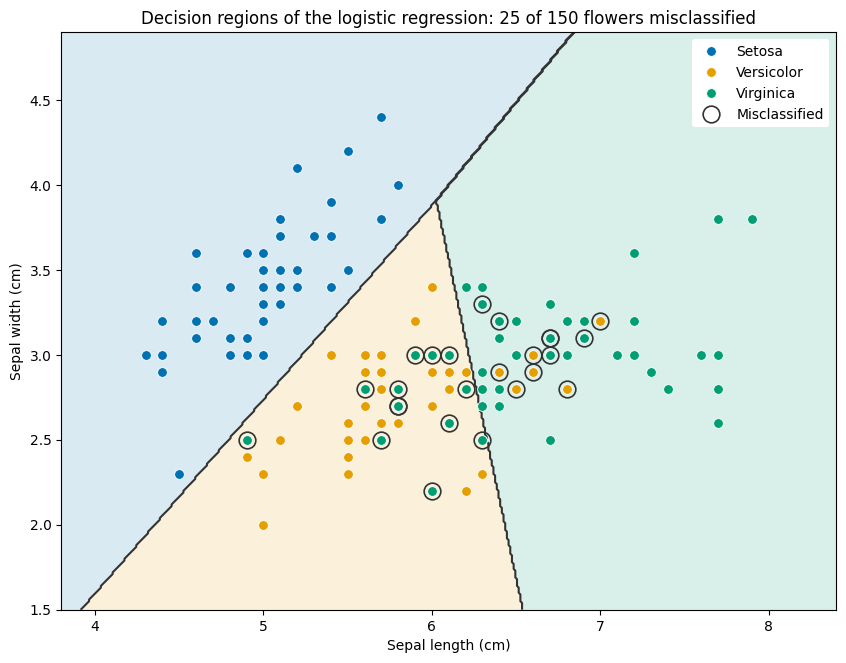

In [5]:
def plot_points(ax, legend=True):
    for k in range(3):
        ax.plot(X[Y == k, 0], X[Y == k, 1], 'o', color=class_colors[k], markersize=7, markeredgecolor='white',
                markeredgewidth=0.6, label=species[k])
    ax.set_xlabel('Sepal length (cm)')
    ax.set_ylabel('Sepal width (cm)')
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=class_colors, alpha=0.15)
ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors='#333333', linewidths=1.5)
plot_points(ax)
wrong = Y_hat != Y
ax.plot(X[wrong, 0], X[wrong, 1], 'o', markersize=12, markerfacecolor='none', markeredgecolor='#333333',
        markeredgewidth=1.2, label='Misclassified')
ax.set_title(f'Decision regions of the logistic regression: {wrong.sum()} of {len(Y)} flowers misclassified')
ax.legend(loc='upper right', framealpha=1, edgecolor='none')

## Estimated probabilities

The regions only show the most probable species. The model gives the probability of each one: it is sure about *setosa*, but *versicolor* and *virginica* overlap in these two features and their probabilities change slowly.

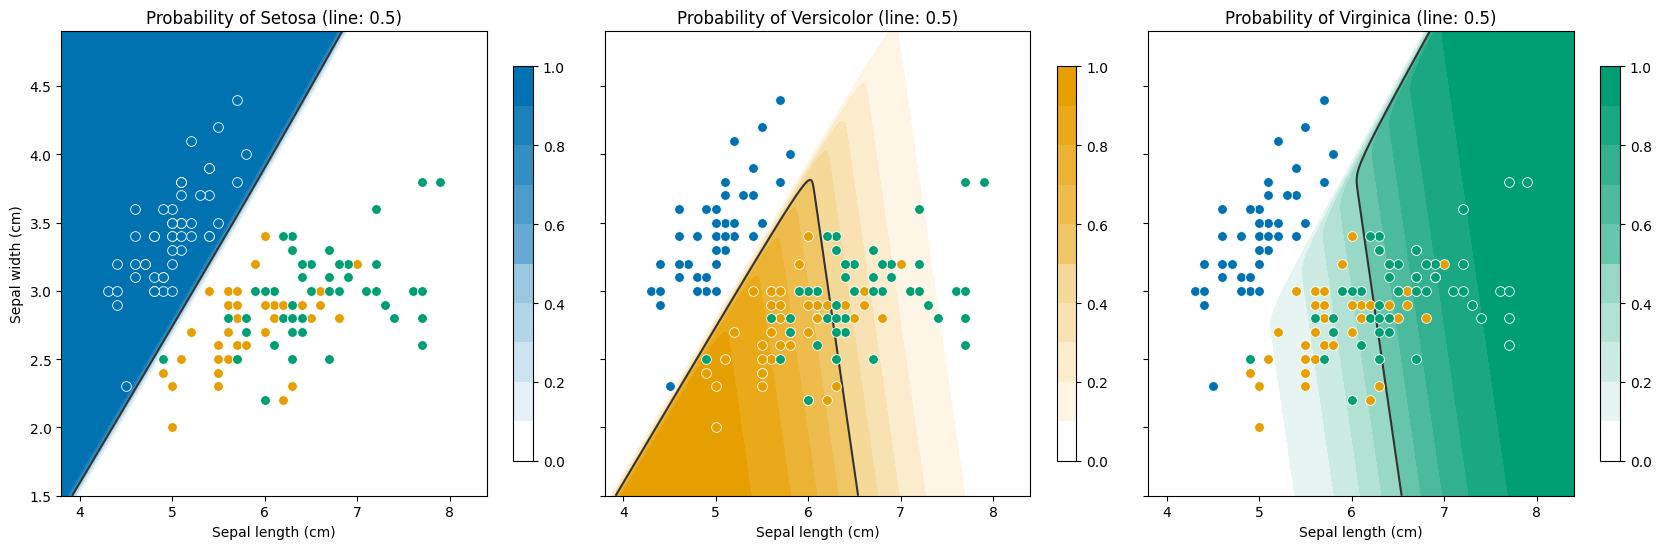

In [6]:
proba = logreg.predict_proba(grid)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
for k, ax in enumerate(axes):
    cmap = ListedColormap(np.linspace([1, 1, 1], plt.matplotlib.colors.to_rgb(class_colors[k]), 11))
    cf = ax.contourf(xx, yy, proba[:, k].reshape(xx.shape), levels=np.linspace(0, 1, 11), cmap=cmap)
    ax.contour(xx, yy, proba[:, k].reshape(xx.shape), levels=[0.5], colors='#333333', linewidths=1.5)
    plot_points(ax)
    ax.set_title(f'Probability of {species[k]} (line: 0.5)')
    fig.colorbar(cf, ax=ax, shrink=0.85)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()

## Confusion matrix

Accuracy: 83.3%


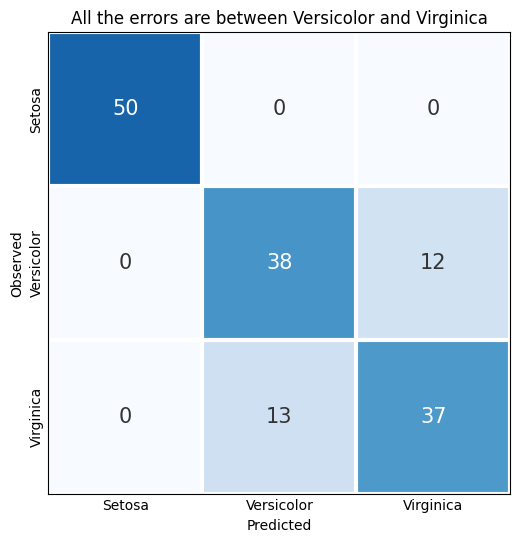

In [7]:
conf_matrix = confusion_matrix(Y, Y_hat)
print(f'Accuracy: {100*np.trace(conf_matrix)/len(Y):.1f}%')

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(conf_matrix, cmap='Blues', vmin=0, vmax=conf_matrix.max()*1.25)
for i in range(3):
    for j in range(3):
        ax.text(j, i, conf_matrix[i, j], ha='center', va='center', fontsize=15,
                color='white' if conf_matrix[i, j] > 0.6*conf_matrix.max() else '#333333')
ax.set_xticks(range(3), species)
ax.set_yticks(range(3), species, rotation=90, va='center')
ax.set_xticks(np.arange(4)-0.5, minor=True)
ax.set_yticks(np.arange(4)-0.5, minor=True)
ax.grid(which='minor', color='white', linewidth=3)
ax.tick_params(which='both', length=0)
ax.set_xlabel('Predicted')
ax.set_ylabel('Observed')
ax.set_title('All the errors are between Versicolor and Virginica');